<a href="https://colab.research.google.com/github/seo104/26-2-ESAA/blob/main/YB_1120_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C_%ED%9A%8C%EA%B7%802.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [1]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [2]:
# 데이터 로드
data = pd.read_csv("/content/abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [3]:
# 필요한 모듈 불러오기
from sklearn.model_selection import train_test_split

In [4]:
# train과 test set 분리 (train:test = 7:3 비율로)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [5]:
#필요한 모듈 불러오기
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [6]:
#릿지모델 생성 및 훈련
ridge_model = Ridge(alpha=0.3)
ridge_model.fit(X_train, y_train)

#예측값 구하기
y_pred = ridge_model.predict(X_test)

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
age_pred = y_pred + 1.5
age_actual = y_test + 1.5

#MSE와 RMSE구하기
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("MSE:", mse)
print("RMSE:", rmse)

print("예측한 전복 나이(앞 5개):", age_pred[:5])
print("실제 전복 나이(앞 5개):", age_actual[:5])

MSE: 4.772148639987027
RMSE: 2.1845248087369087
예측한 전복 나이(앞 5개): [13.39040906 11.83577241 15.46087333 13.56614179 12.58190724]
실제 전복 나이(앞 5개): [10.5  9.5 17.5 10.5 15.5]


3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [7]:
data.columns

Index(['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'M', 'F', 'I'],
      dtype='object')

3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [8]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [9]:
#alphas list 값을 반복하면서 alpha에 따른 평균 rmse를 구함
mean_rmse_list = []

for alpha in alphas:
    ridge_model_cv = Ridge(alpha=alpha)

  #cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산
    neg_rmse_scores = cross_val_score(
        ridge_model_cv, X_train, y_train,
        cv=5, scoring="neg_root_mean_squared_error"
    )
    mean_rmse = -neg_rmse_scores.mean()
    mean_rmse_list.append(mean_rmse)
    print(f"alpha={alpha}: 평균 RMSE={mean_rmse:.4f}")

best_index = np.argmin(mean_rmse_list)
best_alpha = alphas[best_index]
print("가장 좋은 alpha:", best_alpha)
print("최소 평균 RMSE:", mean_rmse_list[best_index])

alpha=0: 평균 RMSE=2.2420
alpha=0.1: 평균 RMSE=2.2282
alpha=1: 평균 RMSE=2.2152
alpha=10: 평균 RMSE=2.3650
alpha=100: 평균 RMSE=2.6364
가장 좋은 alpha: 1
최소 평균 RMSE: 2.2152054224013926


## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [10]:
# 필요한 모듈 임포트
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [11]:
#모델 생성 및 훈련
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    objective="reg:squarederror"
)
xgb_model.fit(X_train, y_train)

#예측값 구하기
xgb_pred = xgb_model.predict(X_test)

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
xgb_age_pred = xgb_pred + 1.5
xgb_age_actual = y_test + 1.5

#MSE와 RMSE 구하기
xgb_mse = mean_squared_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
print("MSE:", xgb_mse)
print("RMSE:", xgb_rmse)

print("예측한 전복 나이(앞 5개):", xgb_age_pred[:5])
print("실제 전복 나이(앞 5개):", xgb_age_actual[:5])

MSE: 4.8719868659973145
RMSE: 2.207257770627915
예측한 전복 나이(앞 5개): [13.592357  11.125499  16.455967  13.024807  13.1770525]
실제 전복 나이(앞 5개): [10.5  9.5 17.5 10.5 15.5]


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

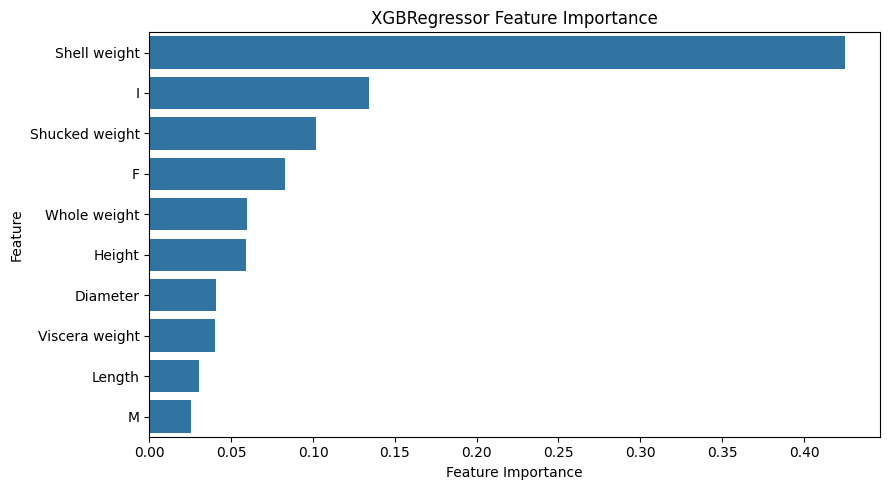

In [12]:
import seaborn as sns
%matplotlib inline
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=data.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=feature_importance.values, y=feature_importance.index)
plt.title("XGBRegressor Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

---

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [13]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [14]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [15]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [16]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [17]:
#기울기
print(logistic_model.coef_)

[[-4.96429625e-01  5.36751015e-01  6.77876404e-01 -2.91296922e-01
   7.42132329e-04  1.35721997e-01  1.01362941e+00  1.14729615e-01
  -9.07912129e-02  4.63017606e-02 -2.24580579e-01  5.37034763e-01
   9.21897462e-03]
 [ 6.42193077e-01 -8.67206745e-01 -7.17360532e-01  1.92521278e-01
  -2.48723088e-02  3.95774753e-01 -9.28541506e-02  2.09352651e-01
   5.88471149e-01 -7.45552918e-01  7.51225052e-01  1.55946921e-01
  -7.86336524e-03]
 [-1.45763452e-01  3.30455730e-01  3.94841275e-02  9.87756432e-02
   2.41301765e-02 -5.31496750e-01 -9.20775255e-01 -3.24082266e-01
  -4.97679936e-01  6.99251158e-01 -5.26644473e-01 -6.92981685e-01
  -1.35560939e-03]]


In [18]:
#절편
print(logistic_model.intercept_)

[-1.07156036  1.44899644 -0.37743608]


3-3) 모델의 정확도를 구하세요.

In [19]:
#모델의 예측값 구하기
y_pred = logistic_model.predict(x_test)

#모델의 정확도 구하기
accuracy = metrics.accuracy_score(y_test, y_pred)
print("정확도:", accuracy)

정확도: 0.9259259259259259
